# 03 · Decision Tree vs Bagging vs Random Forest
Implement the same regression setup on a consistent train/test split. Observe whether bootstrap aggregation reduces instability.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.data import load_data, feature_frame
active=ROOT/'data'/'active_dataset.csv'
if not active.exists():
    raise FileNotFoundError('Run python -m src.train first, then restart the notebook kernel.')
df=load_data(active)
print('Rows, columns:',df.shape)
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from src.models import make_pipeline
x=feature_frame(df,'early'); y=df.G3
indices=np.arange(len(df))
train_idx,test_idx=train_test_split(indices,test_size=.2,stratify=(df.G3<10),random_state=42)
xtr,xt=x.iloc[train_idx],x.iloc[test_idx];ytr,yt=y.iloc[train_idx],y.iloc[test_idx]

Rows, columns: (395, 33)


,model,train_rmse,test_rmse
0,Decision Tree,3.080438,4.076833
1,Bagging,2.333248,3.956428
2,Random Forest,2.103731,3.971787


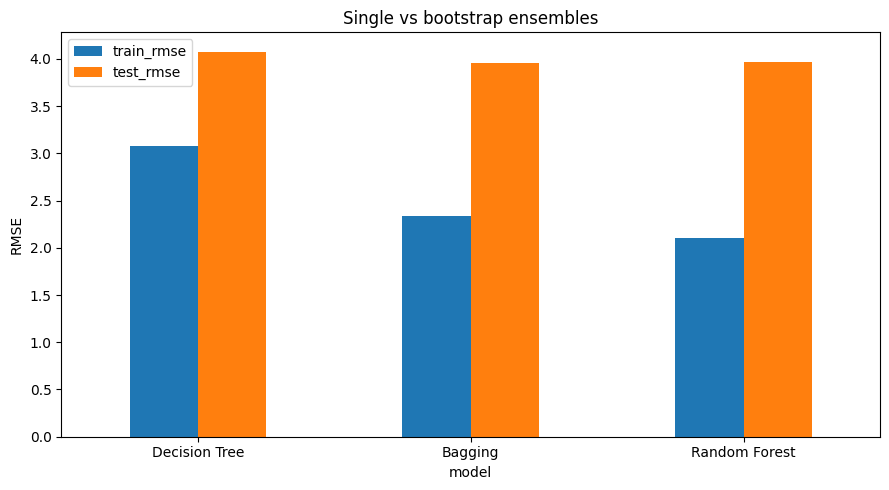

In [2]:
experiments=[]
for name in ['Decision Tree','Bagging','Random Forest']:
    estimator=make_pipeline(name,'grade',xtr)
    estimator.fit(xtr,ytr)
    tr=estimator.predict(xtr);te=estimator.predict(xt)
    experiments.append({'model':name,'train_rmse':np.sqrt(mean_squared_error(ytr,tr)),
                        'test_rmse':np.sqrt(mean_squared_error(yt,te))})
comparison=pd.DataFrame(experiments)
display(comparison)
comparison.set_index('model').plot.bar(rot=0,figsize=(9,5),title='Single vs bootstrap ensembles')
plt.ylabel('RMSE');plt.tight_layout();plt.show()

**Bagging concept:** train many trees using samples drawn *with replacement* and average predictions. **Random Forest** adds random feature subsets per split, helping to decorrelate trees. On tiny datasets, either method can still lose to a simpler alternative.